# Economics S5040 — Problem Set 6 Answer Key
## The Solow Growth Model and U.S. Calibration

**Eric Fisher — Fall 2026**

The analytical parts are solved below. The empirical cells run from the official PWT 11.0 Excel file `pwt110.xlsx`. Numerical U.S. calibration values and figures are generated when this notebook is run with that file present.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Problem 1

The steady state satisfies
$$
k^*=sA(k^*)^\alpha+(1-\delta)k^*,
$$
so
$$
\delta k^*=sA(k^*)^\alpha.
$$
Hence
$$
\boxed{k^*=\left(\frac{sA}{\delta}\right)^{1/(1-\alpha)}}.
$$
Then
$$
\boxed{y^*=A(k^*)^\alpha},\qquad
\boxed{c^*=(1-s)y^*}.
$$
Also,
$$
k_{t+1}-k_t=sAk_t^\alpha-\delta k_t.
$$
Because investment is concave in $k$ while depreciation is linear, investment exceeds depreciation below the positive intersection and falls short above it. Thus capital moves toward $k^*$.

In [2]:
A = 1.0
alpha = 0.33
s = 0.25
delta = 0.08

k_star = (s*A/delta)**(1/(1-alpha))
y_star = A*k_star**alpha
c_star = (1-s)*y_star

print("k* =", k_star)
print("y* =", y_star)
print("c* =", c_star)

k* = 5.477496666261667
y* = 1.7527989332037333
c* = 1.3145991999028


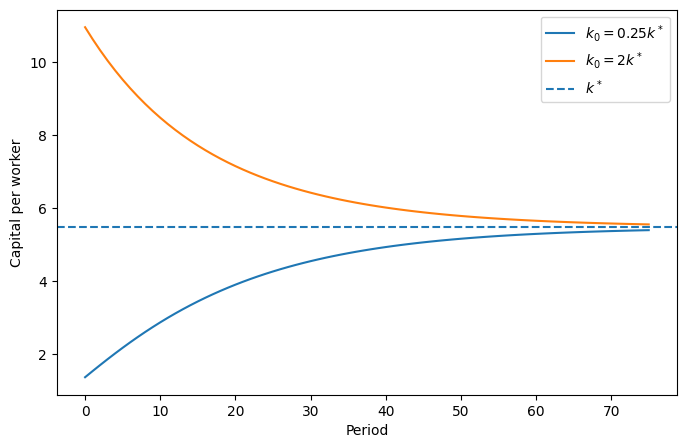

In [3]:
def solow_path(k0, T, A, alpha, s, delta):
    k = np.empty(T+1)
    k[0] = k0
    for t in range(T):
        k[t+1] = s*A*k[t]**alpha + (1-delta)*k[t]
    return k

T=75
low_path = solow_path(0.25*k_star, T, A, alpha, s, delta)
high_path = solow_path(2*k_star, T, A, alpha, s, delta)

plt.figure(figsize=(8,5))
plt.plot(low_path, label=r"$k_0=0.25k^*$")
plt.plot(high_path, label=r"$k_0=2k^*$")
plt.axhline(k_star, linestyle="--", label=r"$k^*$")
plt.xlabel("Period")
plt.ylabel("Capital per worker")
plt.legend()
plt.show()

Both paths converge to the same positive steady state. Below $k^*$, net investment is positive; above $k^*$, net investment is negative.

# Problem 2

Since
$$
K_{t+1}=(1-\delta)K_t+sY_t,
\qquad
L_{t+1}=(1+n)L_t,
$$
we obtain
$$
\boxed{k_{t+1}=\frac{(1-\delta)k_t+sAk_t^\alpha}{1+n}}.
$$
At a steady state,
$$
(1+n)k^*=(1-\delta)k^*+sA(k^*)^\alpha,
$$
so
$$
sA(k^*)^\alpha=(n+\delta)k^*
$$
and
$$
\boxed{k^*=\left(\frac{sA}{n+\delta}\right)^{1/(1-\alpha)}}.
$$
Hence $s\uparrow$ and $A\uparrow$ raise steady-state capital per worker, while $n\uparrow$ and $\delta\uparrow$ lower it.

Under competitive Cobb--Douglas production,
$$
\boxed{w=(1-\alpha)Ak^\alpha},\qquad
\boxed{r=\alpha Ak^{\alpha-1}-\delta}.
$$
Capital deepening raises wages and lowers the return to capital.

With $n=0$, steady-state consumption is $c^*(s)=(1-s)A(k^*(s))^\alpha$. Substituting for $k^*$ and differentiating gives
$$
\boxed{s_{\mathrm{GR}}=\alpha}.
$$
This is not yet a theory of saving because households do not choose $s$ in the Solow model.

# Problem 3 — Penn World Table

In [5]:
pwt_path = Path("pwt110.xlsx")
if not pwt_path.exists():
    raise FileNotFoundError(
        "Place the official PWT 11.0 Excel file pwt110.xlsx in the same directory as this notebook."
    )

pwt = pd.read_excel(pwt_path, sheet_name="Data")
us = pwt.loc[pwt["countrycode"] == "USA"].copy().sort_values("year")
required = ["year", "rgdpna", "rnna", "emp", "labsh", "delta", "rtfpna"]
missing = [c for c in required if c not in us.columns]
assert not missing, f"Missing required PWT variables: {missing}"

print("First year:", int(us["year"].min()))
print("Last year:", int(us["year"].max()))
display(us[required].head())
display(us[required].tail())

First year: 1950
Last year: 2023


,year,rgdpna,rnna,emp,labsh,delta,rtfpna
12950,1950,2709030.50,10666936.0,62.464909,0.628363,0.031030,NaN
12951,1951,2927341.00,11002892.0,64.934853,0.633732,0.031080,NaN
12952,1952,3046543.25,11361193.0,65.829094,0.644852,0.031313,NaN
12953,1953,3189561.00,11763683.0,66.785103,0.644496,0.031630,NaN
12954,1954,3171575.50,12143445.0,65.519707,0.637052,0.031860,0.636467


,year,rgdpna,rnna,emp,labsh,delta,rtfpna
13019,2019,22822856.0,75565584.0,163.923538,0.591833,0.045098,0.964266
13020,2020,22329176.0,76785096.0,154.939697,0.605639,0.045669,0.973078
13021,2021,23681202.0,78158760.0,160.861313,0.593877,0.046234,1.000000
13022,2022,24276130.0,79490152.0,165.578491,0.576183,0.047007,0.984038
13023,2023,24977152.0,80822920.0,167.539749,0.568303,0.047888,0.992998


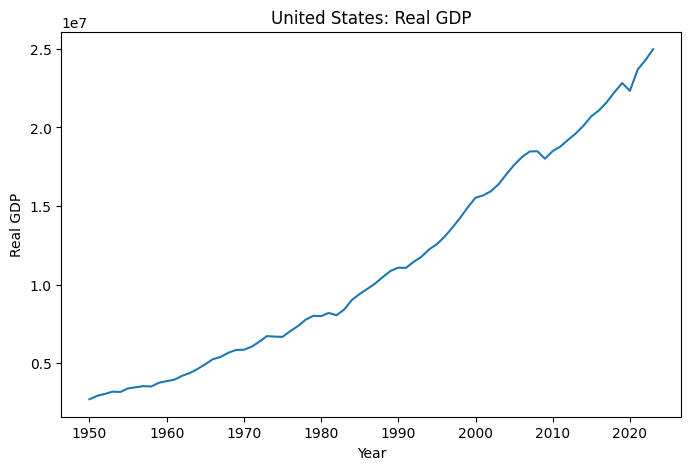

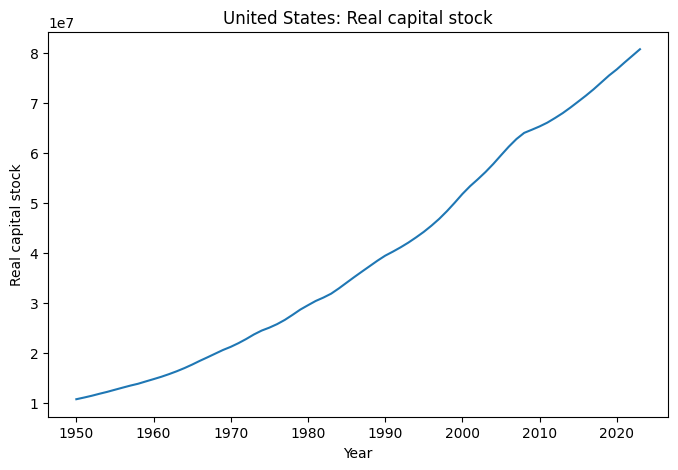

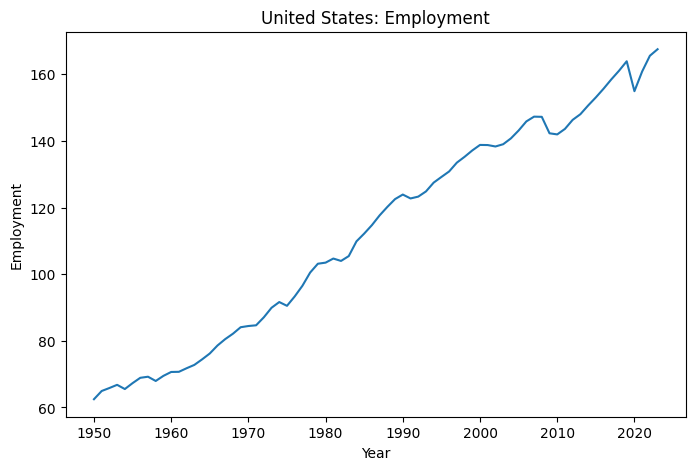

In [6]:
for variable, label in [("rgdpna","Real GDP"),("rnna","Real capital stock"),("emp","Employment")]:
    plt.figure(figsize=(8,5))
    plt.plot(us["year"], us[variable])
    plt.xlabel("Year")
    plt.ylabel(label)
    plt.title(f"United States: {label}")
    plt.show()

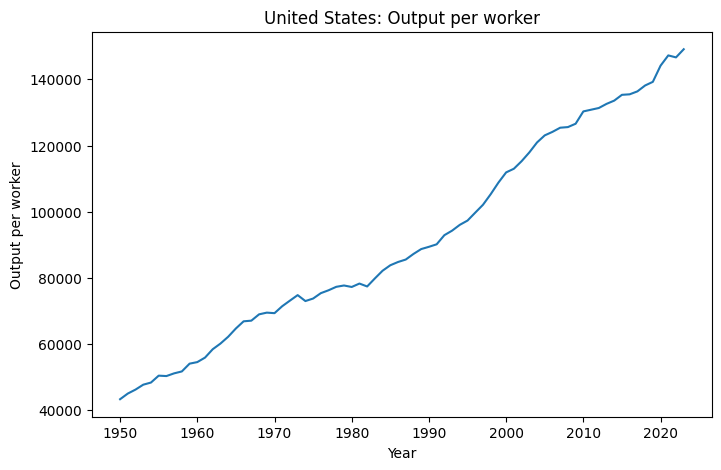

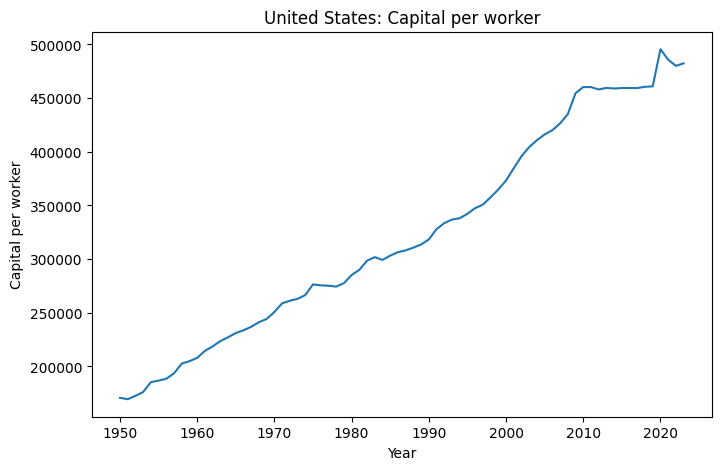

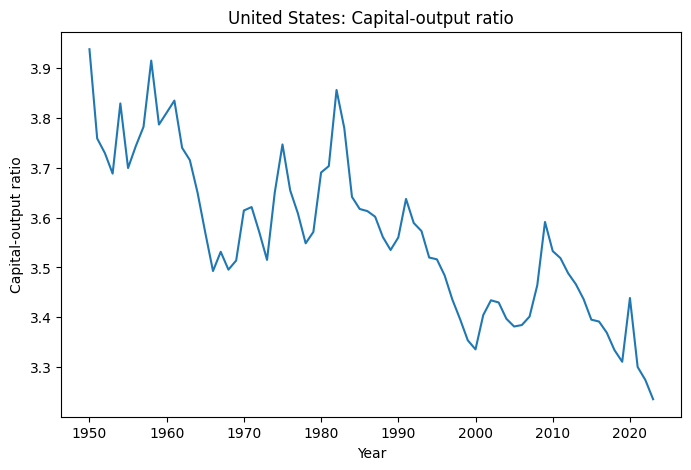

Average labor share = 0.6064318279425305
alpha_hat = 0.3935681720574695
n_hat = 0.009760557336621267


In [7]:
us["y"] = us["rgdpna"] / us["emp"]
us["k"] = us["rnna"] / us["emp"]
us["K_Y"] = us["rnna"] / us["rgdpna"]

for variable, label in [("y","Output per worker"),("k","Capital per worker"),("K_Y","Capital-output ratio")]:
    plt.figure(figsize=(8,5))
    plt.plot(us["year"], us[variable])
    plt.xlabel("Year")
    plt.ylabel(label)
    plt.title(f"United States: {label}")
    plt.show()

bench = us.loc[(us["year"] >= 1990) & (us["year"] <= 2019)].copy()
avg_labsh = bench["labsh"].mean()
alpha_hat = 1 - avg_labsh
bench["emp_growth"] = bench["emp"].shift(-1)/bench["emp"] - 1
n_hat = bench["emp_growth"].dropna().mean()

print("Average labor share =", avg_labsh)
print("alpha_hat =", alpha_hat)
print("n_hat =", n_hat)

The capital share is disciplined by factor-income data rather than chosen arbitrarily. Employment growth supplies the dilution rate in the per-worker law of motion.

# Problem 4 — Capital accumulation, investment, $s$, and $\delta$

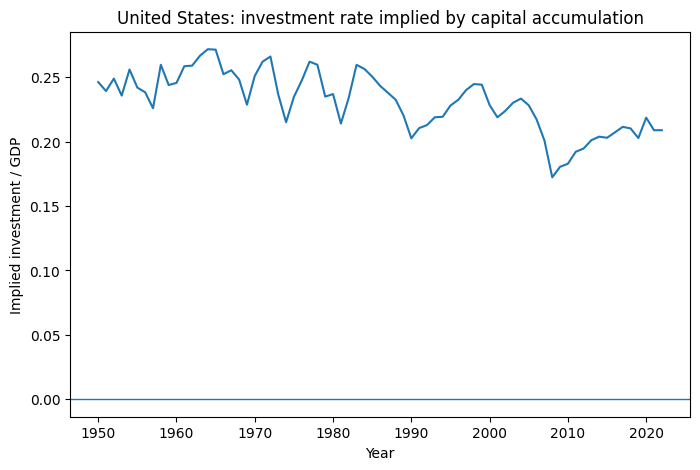

s_hat = 0.2131914712105245
delta_hat = 0.0393713819483916
Average observed K/Y = 3.4511846998064923
Model-implied s/(n+delta) = 4.339162555212961
Difference = 0.8879778554064686


In [8]:
us["K_next"] = us["rnna"].shift(-1)
us["I_implied"] = us["K_next"] - (1-us["delta"])*us["rnna"]
us["s_implied"] = us["I_implied"] / us["rgdpna"]

plt.figure(figsize=(8,5))
plt.plot(us["year"], us["s_implied"])
plt.axhline(0, linewidth=1)
plt.xlabel("Year")
plt.ylabel("Implied investment / GDP")
plt.title("United States: investment rate implied by capital accumulation")
plt.show()

bench = us.loc[(us["year"] >= 1990) & (us["year"] <= 2019)].copy()
s_hat = bench["s_implied"].mean()
delta_hat = bench["delta"].mean()
KY_data = bench["K_Y"].mean()
KY_model = s_hat/(n_hat+delta_hat)

print("s_hat =", s_hat)
print("delta_hat =", delta_hat)
print("Average observed K/Y =", KY_data)
print("Model-implied s/(n+delta) =", KY_model)
print("Difference =", KY_model-KY_data)

The implied investment series comes directly from the capital accumulation identity. The steady-state comparison $K/Y=s/(n+\delta)$ is a diagnostic rather than an identity in the data, because the U.S. need not be in a fixed-technology steady state.

# Problem 5 — Productivity and the U.S. Solow steady state

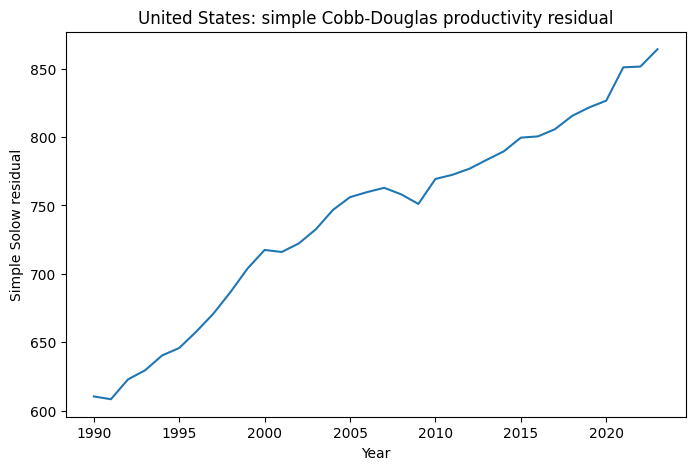

A_2019 = 821.6434811589793
Observed k_2019 = 460980.6793220405
Fixed-A steady-state k*_2019 = 720045.058190625
k_2019 / k*_2019 = 0.6402108785808794


In [9]:
us["A_simple"] = us["y"] / us["k"]**alpha_hat
mask = us["year"] >= 1990
plt.figure(figsize=(8,5))
plt.plot(us.loc[mask,"year"], us.loc[mask,"A_simple"])
plt.xlabel("Year")
plt.ylabel("Simple Solow residual")
plt.title("United States: simple Cobb-Douglas productivity residual")
plt.show()

row2019 = us.loc[us["year"] == 2019].iloc[0]
A_2019 = row2019["A_simple"]
k_2019 = row2019["k"]
k_star_2019 = (s_hat*A_2019/(n_hat+delta_hat))**(1/(1-alpha_hat))

print("A_2019 =", A_2019)
print("Observed k_2019 =", k_2019)
print("Fixed-A steady-state k*_2019 =", k_star_2019)
print("k_2019 / k*_2019 =", k_2019/k_star_2019)

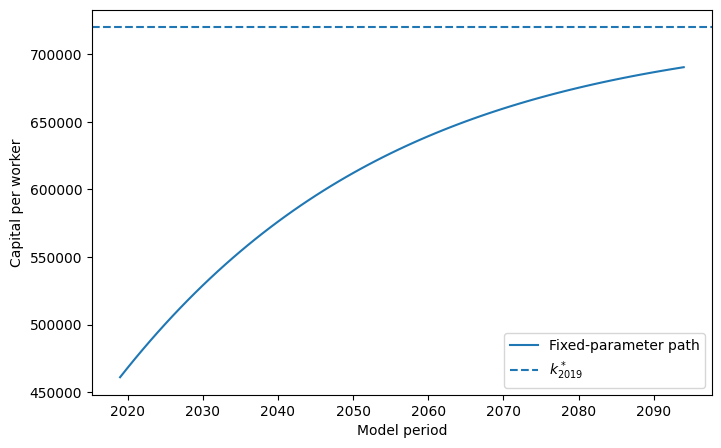

In [10]:
def solow_path_growth(k0, T, A, alpha, s, delta, n):
    k = np.empty(T+1)
    k[0] = k0
    for t in range(T):
        k[t+1] = (s*A*k[t]**alpha + (1-delta)*k[t])/(1+n)
    return k

path = solow_path_growth(k_2019, 75, A_2019, alpha_hat, s_hat, delta_hat, n_hat)
plt.figure(figsize=(8,5))
plt.plot(np.arange(2019, 2019+len(path)), path, label="Fixed-parameter path")
plt.axhline(k_star_2019, linestyle="--", label=r"$k^*_{2019}$")
plt.xlabel("Model period")
plt.ylabel("Capital per worker")
plt.legend()
plt.show()

In [11]:
def h(k, A, alpha, s, delta, n):
    return s*A*k**alpha - (n+delta)*k

def h_prime(k, A, alpha, s, delta, n):
    return alpha*s*A*k**(alpha-1) - (n+delta)

def newton_solow(k0, A, alpha, s, delta, n, tol=1e-12, max_iter=100):
    k = float(k0)
    for it in range(max_iter):
        hp = h_prime(k, A, alpha, s, delta, n)
        if abs(hp) < 1e-14:
            raise RuntimeError("Newton derivative became too small.")
        k_new = k - h(k,A,alpha,s,delta,n)/hp
        if k_new <= 0:
            k_new = 0.5*k
        if abs(k_new-k) < tol*max(1.0,abs(k)):
            return k_new, it+1
        k = k_new
    raise RuntimeError("Newton's method did not converge.")

k_newton, iterations = newton_solow(k_2019, A_2019, alpha_hat, s_hat, delta_hat, n_hat)
print("Newton solution =", k_newton)
print("Analytical solution =", k_star_2019)
print("Absolute difference =", abs(k_newton-k_star_2019))
print("Newton iterations =", iterations)

Newton solution = 720045.0581906249
Analytical solution = 720045.058190625
Absolute difference = 1.1641532182693481e-10
Newton iterations = 5


The fixed-$A_{2019}$ path is not a forecast. Productivity, employment growth, saving, depreciation, and other features of the U.S. economy will not remain permanently fixed at these values. It is a conditional model experiment.

# Problem 6 — Simple residual versus PWT `rtfpna`

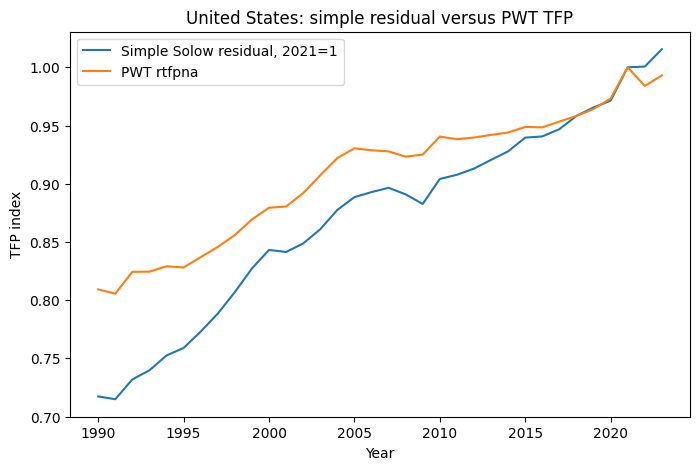

Correlation of annual log growth rates = 0.8092723182584636


In [12]:
A_2021 = us.loc[us["year"] == 2021, "A_simple"].iloc[0]
us["A_simple_norm"] = us["A_simple"]/A_2021
mask = us["year"] >= 1990

plt.figure(figsize=(8,5))
plt.plot(us.loc[mask,"year"], us.loc[mask,"A_simple_norm"], label="Simple Solow residual, 2021=1")
plt.plot(us.loc[mask,"year"], us.loc[mask,"rtfpna"], label="PWT rtfpna")
plt.xlabel("Year")
plt.ylabel("TFP index")
plt.legend()
plt.title("United States: simple residual versus PWT TFP")
plt.show()

us["g_A_simple"] = np.log(us["A_simple_norm"]).diff()
us["g_rtfpna"] = np.log(us["rtfpna"]).diff()
tfp_compare = us.loc[mask,["g_A_simple","g_rtfpna"]].dropna()
corr = tfp_compare.corr().iloc[0,1]
print("Correlation of annual log growth rates =", corr)

The two series should not be identical. Our residual uses one aggregate capital stock, raw employment, and a constant Cobb--Douglas capital share. PWT's `rtfpna` uses a fuller growth-accounting framework, including human capital and a more carefully constructed capital input, with factor shares used in its growth-accounting calculation. Thus `rtfpna` is not simply the classroom residual under another normalization.

In [13]:
us["dlog_y"] = np.log(us["y"]).diff()
us["dlog_A"] = np.log(us["A_simple"]).diff()
us["dlog_k"] = np.log(us["k"]).diff()
us["ga_rhs"] = us["dlog_A"] + alpha_hat*us["dlog_k"]
us["ga_error"] = us["dlog_y"] - us["ga_rhs"]
check = us.loc[us["year"] >= 1990, "ga_error"].dropna()
print("Maximum absolute growth-accounting discrepancy =", np.max(np.abs(check)))

Maximum absolute growth-accounting discrepancy = 1.916869440954372e-15


Because $A_t$ was defined as $y_t/k_t^{\hat\alpha}$, the log growth-accounting relation is an accounting identity up to floating-point rounding.

Calibration changes the exercise from purely qualitative comparative statics to quantitative statements about an actual economy. We can ask how large U.S. parameters appear to be, where the calibrated model places its steady state, and where the simple model misses the data. Those misses then become economically informative.

# What surprised me?

A good response identifies a specific empirical result from the student's own calculations and explains why it was unexpected. There is no single correct answer.